<a href="https://colab.research.google.com/github/kaluarachchiteshan/agromaster-risk-calculation-ml/blob/02-eda/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 02 - Exploratory data analysis (EDA) | Group 41 AgroMaster
# Looks at the modelling subset before cleaning. Nothing is changed here; only figures are saved.
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = "/content/drive/MyDrive/agromaster"
FIG_DIR = os.path.join(OUT_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
DEV_END = pd.Timestamp("2023-12-31")     # end of development period
KEYS = ["state", "district", "market", "commodity", "variety", "grade"]   # one series = one combination
PRICES = ["min_price", "max_price", "modal_price"]

df = pd.read_parquet(os.path.join(OUT_DIR, "agmarknet_subset.parquet"))
df["sid"] = df.groupby(KEYS, observed=True).ngroup()      # integer id per series
df["year"] = df["date"].dt.year
print(df.shape, "| series:", df["sid"].nunique())
df.info()

Mounted at /content/drive
(7919229, 12) | series: 2605
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7919229 entries, 0 to 7919228
Data columns (total 12 columns):
 #   Column       Dtype         
---  ------       -----         
 0   state        category      
 1   district     category      
 2   market       category      
 3   commodity    category      
 4   variety      category      
 5   grade        category      
 6   date         datetime64[ns]
 7   min_price    float32       
 8   max_price    float32       
 9   modal_price  float32       
 10  sid          int64         
 11  year         int32         
dtypes: category(6), datetime64[ns](1), float32(3), int32(1), int64(1)
memory usage: 302.1 MB


In [ ]:
# 1. Summary statistics, missing values, duplicates, data quality problems
print(df[PRICES].describe().T.round(1).to_string())
print("\nMissing values per column:\n" + df[KEYS + ["date"] + PRICES].isna().sum().to_string())
print("\nExact duplicate rows:", int(df.duplicated(KEYS + ["date"] + PRICES).sum()))
print("Same series + date reported more than once:", int(df.duplicated(["sid", "date"]).sum()))

checks = {
    "non-positive modal price": df["modal_price"] <= 0,
    "non-positive min or max":  (df["min_price"] <= 0) | (df["max_price"] <= 0),
    "min > max":                df["min_price"] > df["max_price"],
    "modal below min":          df["modal_price"] < df["min_price"],
    "modal above max":          df["modal_price"] > df["max_price"],
}
q = pd.DataFrame({"rows": {k: int(v.sum()) for k, v in checks.items()}})
q["percent"] = (100 * q["rows"] / len(df)).round(3)
print("\nData quality problems (to be handled in cleaning):\n" + q.to_string())
print("\nModal price percentiles per commodity (INR per quintal):")
print(df.groupby("commodity", observed=True)["modal_price"].quantile([0.001, 0.01, 0.5, 0.99, 0.999]).unstack().round(0).to_string())

                 count    mean     std  min    25%     50%     75%       max
min_price    7919229.0  1499.8  1327.8  0.0  600.0  1100.0  2000.0   90000.0
max_price    7919229.0  1870.5  1526.0  0.0  900.0  1500.0  2500.0  373787.0
modal_price  7919229.0  1719.0  1391.2  1.0  800.0  1300.0  2200.0  125000.0

Missing values per column:
state          0
district       0
market         0
commodity      0
variety        0
grade          0
date           0
min_price      0
max_price      0
modal_price    0

Exact duplicate rows: 0
Same series + date reported more than once: 0

Data quality problems (to be handled in cleaning):
                            rows  percent
non-positive modal price       0    0.000
non-positive min or max   197432    2.493
min > max                   1957    0.025
modal below min                1    0.000
modal above max           188947    2.386

Modal price percentiles per commodity (INR per quintal):
              0.001  0.010   0.500    0.990    0.999
commodit

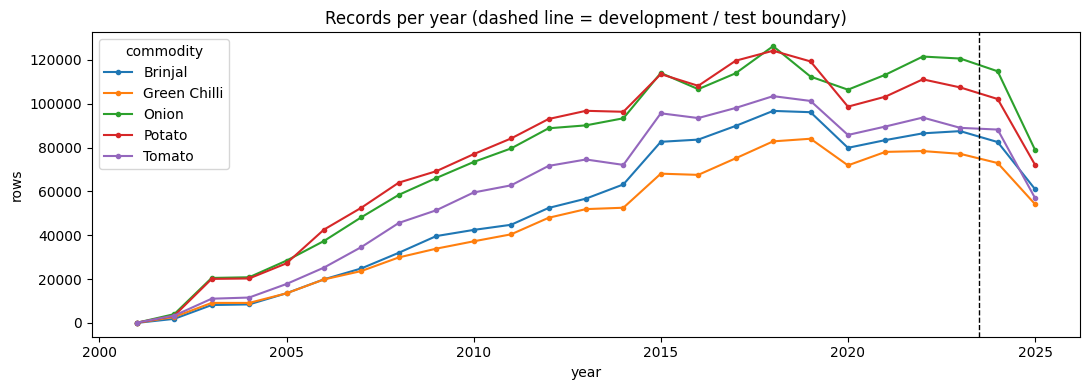

commodity  Brinjal  Green Chilli   Onion  Potato  Tomato
year                                                    
2020         79873         71874  106394   98651   85745
2021         83394         78016  113213  103208   89589
2022         86479         78394  121505  111115   93682
2023         87490         77126  120599  107421   88984
2024         82506         72933  114787  102137   88199
2025         60990         54160   78892   72078   56917

First and last date per commodity:
                    min        max
commodity                         
Brinjal      2001-05-09 2025-11-06
Green Chilli 2001-11-22 2025-11-06
Onion        2001-01-10 2025-11-06
Potato       2001-01-10 2025-11-06
Tomato       2001-02-08 2025-11-05

Series still reporting in each year (last report falls in that year):
date
2020      22
2021      31
2022      30
2023      99
2024     130
2025    1990

Test period rows: 783,599 (9.9%) | series with test data: 2,120 of 2,605


In [ ]:
# 2. Coverage: rows per commodity and year, and where each commodity's data ends
tab = df.pivot_table(index="year", columns="commodity", values="modal_price", aggfunc="size", fill_value=0, observed=True)
ax = tab.plot(figsize=(11, 4), marker="o", ms=3)
ax.axvline(DEV_END.year + 0.5, color="k", ls="--", lw=1)
ax.set_ylabel("rows"); ax.set_title("Records per year (dashed line = development / test boundary)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "02_rows_per_year.png"), dpi=150); plt.show()

print(tab.tail(6).to_string())
print("\nFirst and last date per commodity:")
print(df.groupby("commodity", observed=True)["date"].agg(["min", "max"]).to_string())
last = df.groupby("sid")["date"].max()
print("\nSeries still reporting in each year (last report falls in that year):")
print(last.dt.year.value_counts().sort_index().tail(6).to_string())
test = df[df["date"] > DEV_END]
print(f"\nTest period rows: {len(test):,} ({100 * len(test) / len(df):.1f}%) | "
      f"series with test data: {test['sid'].nunique():,} of {df['sid'].nunique():,}")

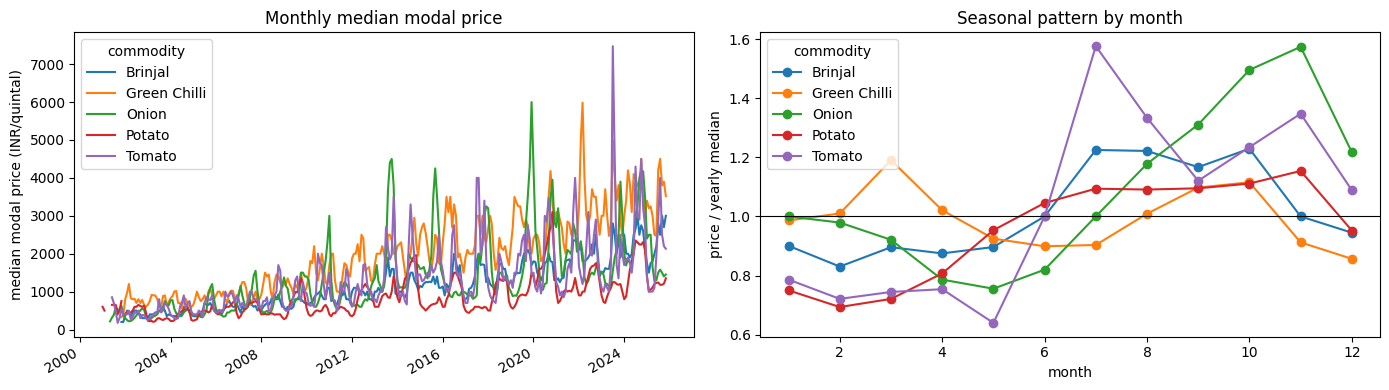

Seasonal index (1.00 = yearly median):
commodity  Brinjal  Green Chilli  Onion  Potato  Tomato
month                                                  
1             0.90          0.99   1.00    0.75    0.79
2             0.83          1.01   0.98    0.69    0.72
3             0.90          1.19   0.92    0.72    0.74
4             0.88          1.02   0.79    0.81    0.75
5             0.90          0.92   0.76    0.95    0.64
6             1.00          0.90   0.82    1.05    1.00
7             1.22          0.90   1.00    1.09    1.58
8             1.22          1.01   1.18    1.09    1.33
9             1.17          1.10   1.31    1.10    1.12
10            1.23          1.12   1.50    1.11    1.23
11            1.00          0.91   1.57    1.15    1.35
12            0.95          0.86   1.22    0.95    1.09

Median modal price by year (shows inflation drift):
commodity  Brinjal  Green Chilli   Onion  Potato  Tomato
year                                                    
2001      

In [ ]:
# 3. Price level over time and seasonal pattern
pos = df[df["modal_price"] > 0]
month_start = pos["date"].values.astype("datetime64[M]")
monthly = pos.groupby([month_start, pos["commodity"]], observed=True)["modal_price"].median().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly.plot(ax=axes[0]); axes[0].set_ylabel("median modal price (INR/quintal)"); axes[0].set_xlabel("")
axes[0].set_title("Monthly median modal price")

# Seasonality: each month's median relative to that year's median, so inflation does not hide the pattern
ym = pos.groupby(["commodity", "year", pos["date"].dt.month.rename("month")], observed=True)["modal_price"].median().reset_index()
ym["rel"] = ym["modal_price"] / ym.groupby(["commodity", "year"], observed=True)["modal_price"].transform("median")
season = ym.groupby(["month", "commodity"], observed=True)["rel"].median().unstack()
season.plot(ax=axes[1], marker="o"); axes[1].axhline(1, color="k", lw=0.8)
axes[1].set_ylabel("price / yearly median"); axes[1].set_title("Seasonal pattern by month")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "02_price_trend_seasonality.png"), dpi=150); plt.show()

print("Seasonal index (1.00 = yearly median):\n" + season.round(2).to_string())
print("\nMedian modal price by year (shows inflation drift):")
print(pos.groupby(["year", "commodity"], observed=True)["modal_price"].median().unstack().iloc[::4].round(0).to_string())

In [ ]:
# 4. Reporting gaps: mandi prices are not reported every day (proposal forward-fills at most 3 days)
d = df[["sid", "date"]].drop_duplicates().sort_values(["sid", "date"])
gap = d.groupby("sid")["date"].diff().dt.days.dropna()
bins = pd.cut(gap, [0, 1, 2, 4, 7, 30, 1e6], labels=["1 day (no gap)", "2 days", "3-4 days", "5-7 days", "8-30 days", "over 30 days"])
print("Days between consecutive reports in a series (% of reports):")
print(bins.value_counts(normalize=True).sort_index().mul(100).round(2).to_string())
print(f"\nGaps a 3-day forward-fill can bridge (next report within 4 days): {100 * (gap <= 4).mean():.1f}%")
per_series = d.groupby("sid").size()
print("\nReporting days per series:", per_series.describe().round(0).to_dict())

Days between consecutive reports in a series (% of reports):
date
1 day (no gap)    77.54
2 days            13.27
3-4 days           6.05
5-7 days           1.82
8-30 days          1.02
over 30 days       0.29

Gaps a 3-day forward-fill can bridge (next report within 4 days): 96.9%

Reporting days per series: {'count': 2605.0, 'mean': 3040.0, 'std': 1031.0, 'min': 1502.0, '25%': 2252.0, '50%': 2822.0, '75%': 3674.0, 'max': 7181.0}
